# Frontieres-09 — RCPSP/max : quand la faisabilité devient le problème

[Version Python](Frontieres-09-RCPSP-Max-Feasibility-Bounds-Python.ipynb) · [Parcours Partie 5](README.md)


## Décalages généralisés, circuits de poids positif, et ce qu'une borne gratuite dit d'un banc d'essai

[← Partie 5](README.md) | [↑ Search](../README.md) | [>> Frontieres-10 Neural diving](Frontieres-10-NeuralDiving-Coloration-Python.ipynb)

Cette application prolonge le projet **B4 — Ordonnancement industriel** d'**Arthur Gallier** et
**Nicolas Naegelen** (EPITA SCIA, *Programmation par Contraintes* 2026 :
[rendu source](https://github.com/jsboigeEpita/2026-Epita-Programmation-par-Contraintes)).

Leur rendu réunit un parseur PSPLIB écrit à la main, un modèle CP-SAT du RCPSP, une baseline
génétique à croisement préservant les précédences, un banc d'essai sur j30/j60/j120, une étude
de stratégies de branchement, une ouverture RCPSP/max et une ouverture multi-mode. C'est ce
geste — poser côte à côte l'exact et l'approché sur un benchmark public — que ce notebook
prolonge.

Il le prolonge sur un point précis. La section RCPSP/max du rendu pose le bon modèle général,
par décalages `start[j] - start[i] >= delta`. Mais un décalage négatif *minimum* est un
assouplissement, tandis qu'un lag *maximal* est d'une autre nature : il s'encode par un **arc
inverse**, crée un **circuit** dans le réseau temporel, et fait basculer la **faisabilité
elle-même** dans NP-difficile. En RCPSP pur, au contraire, on sait toujours produire un
ordonnancement réalisable. Ce notebook construit cette bascule, la détecte et la mesure.

**Ce que ce notebook établit :**

1. un lag maximal introduit un circuit, et seul un circuit de **poids positif** rend infaisable ;
2. l'infaisabilité *temporelle* se certifie en temps polynomial, sans solveur, avec un témoin
   vérifiable à la main ;
3. l'infaisabilité *en ressources* ne se certifie pas ainsi — d'où trois régimes à distinguer ;
4. quand une référence externe manque, une **hiérarchie de bornes** calculables remplace une
   colonne d'écart vide par une garantie plus faible, mais mesurée.

> **Note de méthode.** Les dix makespans publiés par le banc d'essai source ont été recalculés
> pour l'audit archivé avec un modèle écrit indépendamment : **les dix sont exacts**, tous certifiés
> `OPTIMAL`. Rien dans ce notebook ne met en cause un résultat numérique du rendu étudiant.

**Trois exercices restent ouverts.** Les sections 3, 5 et 7 en proposent trois : **(1)** décider la faisabilité temporelle sans calculer les dates, **(2)**
traduire une exigence industrielle en arc — au bon sens et au bon signe, **(3)** écrire la
borne de charge. Chacun s'exécute tel quel et affiche « à compléter » : aucune exception,
aucune cellule en erreur. Les cellules de vérification qui suivent chaque stub comparent
votre réponse à une implémentation de référence et affichent un verdict chiffré.

**Prérequis** : `CSP-04-Scheduling-Python` pour le RCPSP et les contraintes cumulatives. Durée estimée
60 à 75 minutes.

**Objectifs d’apprentissage** — Représenter un lag maximal, vérifier un circuit positif, distinguer les causes d’infaisabilité et comparer les niveaux de preuve.

**Environnement** — .NET C# et Google.OrTools. Les activités PSPLIB lisent les observations documentées du banc d’origine.

## 1. L'exercice que le cours laissait ouvert

CoursIA enseigne déjà le RCPSP : `CSP-04-Scheduling-Python` lui consacre une section entière, et
`Planners-08-Temporal-Python` le traite du côté planification. Ce dernier notebook referme d'ailleurs
le sujet sur une phrase restée sans suite :

> « la comparaison avec l'optimum known d'un benchmark (ex: PSPLIB) est laissée en exercice. »

C'est précisément l'exercice que le groupe B4 a traité. Ce notebook ne le refait donc pas : il
part de là où leur banc d'essai s'arrête, sur les deux questions qu'un benchmark
d'ordonnancement soulève dès qu'on le regarde de près — *que vaut ma référence quand la
jointure échoue ?* et *que devient le problème quand le réseau temporel cesse d'être acyclique ?*

Fixons d'abord l'environnement.

In [1]:
#nullable enable
#r "nuget: Google.OrTools, 9.15.6755"

using System;
using System.Collections.Generic;
using System.Diagnostics;
using System.Globalization;
using System.IO;
using System.Linq;
using System.Numerics;
using System.Security.Cryptography;
using System.Text;
using System.Text.Json;
using Google.OrTools.Sat;
using Microsoft.DotNet.Interactive.Formatting;

CultureInfo.DefaultThreadCurrentCulture = CultureInfo.InvariantCulture;
CultureInfo.DefaultThreadCurrentUICulture = CultureInfo.InvariantCulture;

// Les rapports de ce run ne recouvrent pas les observations historiques du dossier data.
var reportDirectory = Directory.CreateTempSubdirectory("rcpsp-csharp-");
var jsonOptions = new JsonSerializerOptions { WriteIndented = true };
record SvgFigure(string Content);
Formatter.Register<SvgFigure>((figure, context) =>
{
    context.Writer.Write(figure.Content);
    return true;
}, "image/svg+xml");
Formatter.SetPreferredMimeTypesFor(typeof(SvgFigure), new[] { "image/svg+xml" });

var environment = new
{
    dotnet = Environment.Version.ToString(),
    platform = Environment.OSVersion.Platform.ToString(),
    ortools = typeof(CpSolver).Assembly.GetName().Version?.ToString()
};
Console.WriteLine($"Environnement mesuré : .NET {environment.dotnet} | {environment.platform} | OR-Tools {environment.ortools}");
Console.WriteLine("Sorties fraîches : régimes temporels, bornes et provenance dans un répertoire temporaire distinct.");

Installed Packages Google.OrTools, 9.15.6755

Environnement mesuré : .NET 10.0.14 | Unix | OR-Tools 9.15.6755.0


Sorties fraîches : régimes temporels, bornes et provenance dans un répertoire temporaire distinct.


La version .NET et celle d’OR-Tools sont relevées dès la première cellule et sera recopié dans `provenance.json`.
Tout temps de résolution publié plus bas reste ainsi rattachable à une version de solveur
précise : un chiffre de performance sans version d'OR-Tools n'est pas une mesure reproductible.

## 2. Le réseau temporel — une seule inégalité pour tout dire

Tout ce qui suit tient dans une forme unique. Entre deux tâches $i$ et $j$, une contrainte
temporelle s'écrit

$$s_j - s_i \ \geq\ \delta_{ij}$$

où $s_i$ désigne la date de début de $i$. C'est un **système de contraintes de différences**, et
il suffit à exprimer tout le vocabulaire courant de l'ordonnancement :

| Ce qu'on veut dire | Arc posé | Poids |
|---|---|---|
| $j$ suit la fin de $i$ (précédence classique) | $i \to j$ | $+d_i$ |
| $j$ ne démarre pas avant 5 unités après le début de $i$ | $i \to j$ | $+5$ |
| $j$ peut démarrer jusqu'à 2 unités **avant** la fin de $i$ | $i \to j$ | $d_i - 2$ |
| $j$ doit démarrer **au plus** 7 unités après $i$ | $j \to i$ | $-7$ |

Les trois premières lignes sont des **décalages minimaux** : leurs arcs pointent tous de $i$
vers $j$. Un poids négatif y relâche la contrainte — il autorise du recouvrement — mais ne
change pas la nature du graphe : si le réseau était acyclique, il le reste.

La quatrième ligne est d'une autre espèce. C'est un **lag maximal**, et son arc pointe à
l'envers. Il referme un circuit. Toute la suite découle de cette asymétrie.

In [2]:
#nullable enable
record TemporalArc(int From, int To, int Offset);

// Un seul sens d'arc représente toutes les contraintes : date[To] >= date[From] + Offset.
class TemporalNetwork
{
    public int Count { get; }
    public List<TemporalArc> Arcs { get; } = new();
    public TemporalNetwork(int count) => Count = count;

    public void AddMinLag(int from, int to, int offset) => Arcs.Add(new(from, to, offset));
    public void AddPrecedence(int from, int to, int duration) => AddMinLag(from, to, duration);
    public void AddMaxLag(int from, int to, int offset) => AddMinLag(to, from, -offset);

    public bool HasCycle()
    {
        // Ce tri topologique détecte tout circuit, quel que soit son poids.
        var inDegree = new int[Count];
        var successors = Arcs.ToLookup(arc => arc.From, arc => arc.To);
        foreach (var arc in Arcs) inDegree[arc.To]++;
        var queue = new Queue<int>(Enumerable.Range(0, Count).Where(i => inDegree[i] == 0));
        int visited = 0;
        while (queue.TryDequeue(out int node))
        {
            visited++;
            foreach (int next in successors[node])
                if (--inDegree[next] == 0)
                    queue.Enqueue(next);
        }
        return visited != Count;
    }
}

int[] durationsDemo = { 3, 4, 2, 5 };
TemporalNetwork BasicChain()
{
    var graph = new TemporalNetwork(durationsDemo.Length);
    for (int i = 0; i + 1 < durationsDemo.Length; i++)
        graph.AddPrecedence(i, i + 1, durationsDemo[i]);
    return graph;
}

var minCase = BasicChain();
minCase.AddMinLag(1, 2, durationsDemo[1] - 2);
var maxCase = BasicChain();
maxCase.AddMaxLag(1, 3, 6);
foreach (var (name, graph) in new[]
{
    ("Précédences seules", BasicChain()),
    ("+ minimum avec recouvrement", minCase),
    ("+ lag maximal (≤ 6)", maxCase)
})
    Console.WriteLine($"{name,-30} {graph.Arcs.Count} arcs | circuit : {graph.HasCycle()}");

Précédences seules             3 arcs | circuit : False


+ minimum avec recouvrement    4 arcs | circuit : False


+ lag maximal (≤ 6)            4 arcs | circuit : True


La distinction tient en trois lignes de sortie. Un décalage minimal **négatif** laisse le
graphe acyclique : c'est un relâchement, il autorise du recouvrement, rien de plus. Seul le lag
**maximal** referme un circuit.

C'est exactement ce qu'une formulation générale `start[j] - start[i] >= delta` peut porter sans
qu'on le remarque : le modèle est correct pour les deux cas, mais tant qu'on ne pose que des
arcs directs, on reste dans le monde acyclique — donc dans le RCPSP ordinaire — quel que soit
le signe des poids.

## 3. Le circuit n'est pas le problème — le circuit **positif** l'est

Un circuit n'interdit rien en soi. Reprenons celui que le lag maximal vient de créer. Il est
formé de deux arcs :

$$s_2 - s_1 \geq d_1 = 4 \qquad \text{et} \qquad s_1 - s_2 \geq -6$$

En additionnant membre à membre, les inconnues disparaissent et il reste $0 \geq 4 - 6 = -2$.
C'est vrai : le circuit est de poids **négatif**, il n'interdit rien. La contrainte « démarrer
au plus 6 unités après » est simplement plus lâche que ce que la précédence impose déjà.

Resserrons-la à 3. La somme devient $0 \geq 4 - 3 = 1$, ce qui est faux. Le circuit est de poids
**positif** et le système n'admet aucune solution — indépendamment de toute ressource, de toute
capacité et de tout solveur.

D'où le critère général : *un système de contraintes de différences admet une solution si et
seulement si son digraphe ne contient aucun circuit de poids strictement positif.* Et ce critère
se teste en temps polynomial.

In [3]:
#nullable enable
(bool Feasible, int[]? Dates, int[]? Circuit) EarliestDates(TemporalNetwork graph)
{
    // Une source virtuelle de poids zéro atteint chaque nœud. On cherche les plus longs chemins.
    var dates = new int[graph.Count];
    var parents = new int[graph.Count];
    int touched = -1;
    for (int round = 0; round <= graph.Count; round++)
    {
        touched = -1;
        foreach (var arc in graph.Arcs)
        {
            // L’arc impose une borne inférieure sur la date cible. On ne propage que sa hausse.
            int candidate = dates[arc.From] + arc.Offset;
            if (candidate <= dates[arc.To]) continue;
            dates[arc.To] = candidate;
            parents[arc.To] = arc.From;
            touched = arc.To;
        }
        // Une passe stable a satisfait toutes les inégalités sur la date courante.
        if (touched < 0) return (true, dates, null);
    }

    // Remonter n prédécesseurs quitte toute queue du chemin et entre dans le circuit.
    int first = touched;
    for (int i = 0; i < graph.Count; i++) first = parents[first];
    var reverse = new List<int> { first };
    for (int v = parents[first]; v != first; v = parents[v]) reverse.Add(v);
    reverse.Add(first);
    reverse.Reverse();
    return (false, null, reverse.ToArray());
}

int CycleWeight(TemporalNetwork graph, int[] circuit)
{
    // Pour des arcs parallèles, la contrainte de plus grand décalage est la plus forte.
    var heaviest = graph.Arcs.GroupBy(arc => (arc.From, arc.To))
        .ToDictionary(group => group.Key, group => group.Max(arc => arc.Offset));
    return circuit.Zip(circuit.Skip(1), (from, to) => heaviest[(from, to)]).Sum();
}

foreach (int maximum in new[] { 6, 5, 4, 3 })
{
    var graph = BasicChain();
    graph.AddMaxLag(1, 3, maximum);
    var result = EarliestDates(graph);
    if (result.Feasible)
        Console.WriteLine($"Lag maximal ≤ {maximum} | FAISABLE | dates [{string.Join(", ", result.Dates!)}]");
    else
        Console.WriteLine($"Lag maximal ≤ {maximum} | INFAISABLE | circuit {string.Join(" → ", result.Circuit!)} | poids +{CycleWeight(graph, result.Circuit!)}");
}

Lag maximal ≤ 6 | FAISABLE | dates [0, 3, 7, 9]


Lag maximal ≤ 5 | INFAISABLE | circuit 3 → 1 → 2 → 3 | poids +1


Lag maximal ≤ 4 | INFAISABLE | circuit 3 → 1 → 2 → 3 | poids +2


Lag maximal ≤ 3 | INFAISABLE | circuit 3 → 1 → 2 → 3 | poids +3


Le témoin est ce qui sépare un diagnostic d'un simple verdict. Un solveur qui répond
`INFEASIBLE` affirme ; ici le circuit exhibé **se vérifie à la main** : on somme les poids le
long du chemin, on obtient une quantité strictement positive, donc l'inégalité impossible
$0 \geq p > 0$. La preuve ne dépend pas du programme qui l'a trouvée.

On lit aussi le seuil exact : la bascule se produit entre 5 et 4, c'est-à-dire dès que la borne
supérieure passe sous la durée cumulée que les précédences imposent déjà. C'est le premier des
deux régimes d'infaisabilité — et le seul qui soit bon marché.

### Exercice 1 — Détecter un circuit de poids positif

Complétez `ExercisePositiveCycle` pour décider si le réseau contient un circuit de poids strictement positif. Rendez un booléen sans calculer les dates de début. Le contrôle compare votre résultat à la relaxation sur six limites.

Les squelettes restent exécutables et affichent « à compléter » tant que la réponse manque.

In [4]:
#nullable enable
// Exercice 1 : renvoyer vrai ou faux après le diagnostic, sans rendre de dates.
bool? ExercisePositiveCycle(TemporalNetwork graph)
{
    // TODO étudiant : tester la possibilité d'améliorer encore une date après les relaxations.
    return null;
}
int comparedCycles = 0;
int correctCycles = 0;
foreach (int limit in new[] { 8, 6, 5, 4, 3, 2 })
{
    var graph = BasicChain();
    graph.AddMaxLag(1, 3, limit);
    var student = ExercisePositiveCycle(graph);
    bool expected = !EarliestDates(graph).Feasible;
    if (student is bool answer)
    {
        comparedCycles++;
        if (answer == expected) correctCycles++;
        Console.WriteLine($"Lag {limit} | réponse {answer} | attendu {expected}");
    }
}
Console.WriteLine(comparedCycles == 0 ? "Exercice 1 à compléter." : $"{correctCycles}/6 résultats corrects.");

Exercice 1 à compléter.


Le point de l'exercice n'est pas l'algorithme, qui tient en quelques lignes, mais ce qu'il
autorise à dire. Une fonction qui répond `True` ici produit une **preuve d'infaisabilité en
temps polynomial** — quelque chose qu'aucun appel à un solveur ne fournit, puisqu'un solveur
qui répond `INFEASIBLE` ne rend pas de certificat vérifiable à la main.

C'est aussi le test qu'il faut placer *avant* le solveur dans tout pipeline RCPSP/max.

## 4. La bascule de complexité — pourquoi le RCPSP pur est confortable

Voici le fait dont tout le reste découle. En **RCPSP pur**, produire un ordonnancement
réalisable est facile : il suffit de prendre les tâches dans un ordre topologique et de placer
chacune au plus tôt là où les capacités le permettent. Cet **ordonnancement série** ne se bloque
jamais, dès lors qu'aucune tâche ne demande à elle seule plus qu'une capacité. Repousser une
tâche ne viole jamais rien, puisque aucune contrainte ne dit « pas plus tard que ».

Toute la difficulté du RCPSP est donc dans l'**optimisation** : trouver *le meilleur*
ordonnancement est NP-difficile, mais en trouver *un* est immédiat.

Ajoutez un lag maximal, et cette garantie tombe. Repousser une tâche peut désormais violer une
borne supérieure, et rien ne dit qu'un autre ordre s'en sortirait. Bartusch, Möhring et
Radermacher l'ont établi en 1988 : pour le RCPSP/max, **décider s'il existe un ordonnancement
réalisable est déjà NP-difficile**. Ce n'est plus l'optimisation qui est dure, c'est la question
préalable.

Vérifions les deux moitiés de cette affirmation.

In [5]:
#nullable enable
// Compatible avec random.Random pour les graines entières positives et les deux tirages employés.
// L'algorithme MT19937 conserve exactement les instances et l'ordre de tirage du carnet Python.
class SeededDraws
{
    private const int StateSize = 624;
    private const int Offset = 397;
    private readonly uint[] state = new uint[StateSize];
    private int index = StateSize;

    public SeededDraws(uint seed)
    {
        unchecked
        {
            state[0] = 19650218;
            for (int i = 1; i < StateSize; i++)
                state[i] = 1812433253U * (state[i - 1] ^ (state[i - 1] >> 30)) + (uint)i;

            int position = 1;
            // init_by_array avec un mot de graine. Le retour à l'indice 1 recopie
            // la dernière case dans la première pour préserver l'ordre de mélange.
            for (int round = 0; round < StateSize; round++)
            {
                uint previous = state[position - 1];
                state[position] = (state[position] ^ ((previous ^ (previous >> 30)) * 1664525U)) + seed;
                if (++position == StateSize)
                {
                    state[0] = state[StateSize - 1];
                    position = 1;
                }
            }
            for (int round = 0; round < StateSize - 1; round++)
            {
                uint previous = state[position - 1];
                state[position] = (state[position] ^ ((previous ^ (previous >> 30)) * 1566083941U)) - (uint)position;
                if (++position == StateSize)
                {
                    state[0] = state[StateSize - 1];
                    position = 1;
                }
            }
            state[0] = 0x80000000U;
        }
    }

    private uint NextWord()
    {
        if (index == StateSize)
        {
            for (int i = 0; i < StateSize; i++)
            {
                uint combined = (state[i] & 0x80000000U) | (state[(i + 1) % StateSize] & 0x7fffffffU);
                uint twist = (combined & 1) == 0 ? 0U : 0x9908b0dfU;
                state[i] = state[(i + Offset) % StateSize] ^ (combined >> 1) ^ twist;
            }
            index = 0;
        }
        uint word = state[index++];
        word ^= word >> 11;
        word ^= (word << 7) & 0x9d2c5680U;
        word ^= (word << 15) & 0xefc60000U;
        return word ^ (word >> 18);
    }

    public double NextUnit() =>
        ((NextWord() >> 5) * 67108864.0 + (NextWord() >> 6)) / 9007199254740992.0;

    public int NextInclusive(int lower, int upper)
    {
        // Rejet des tirages excédentaires, sans biais de réduction modulo.
        uint count = (uint)(upper - lower + 1);
        int shift = 31 - BitOperations.Log2(count);
        uint sample = NextWord() >> shift;
        while (sample >= count) sample = NextWord() >> shift;
        return lower + (int)sample;
    }
}

record RcpspInstance(int[] Durations, int[][] Needs, int[] Capacity, (int From, int To)[] Precedences)
{
    public int Count => Durations.Length;
    public IEnumerable<int> Tasks => Enumerable.Range(0, Count);
}

RcpspInstance RandomInstance(int count, int seed, double density = 0.28, int resources = 2)
{
    var draws = new SeededDraws((uint)seed);
    var durations = Enumerable.Range(0, count).Select(_ => draws.NextInclusive(1, 6)).ToArray();
    var capacity = Enumerable.Range(0, resources).Select(_ => draws.NextInclusive(4, 7)).ToArray();
    var needs = durations.Select(_ => capacity.Select(c => draws.NextInclusive(0, c)).ToArray()).ToArray();
    var precedences = new List<(int From, int To)>();
    for (int i = 0; i < count; i++)
        for (int j = i + 1; j < count; j++)
            if (draws.NextUnit() < density)
                precedences.Add((i, j));
    return new(durations, needs, capacity, precedences.ToArray());
}

(bool Valid, Dictionary<int, int> Dates) SerialSchedule(RcpspInstance instance, int horizon)
{
    // Une copie par instant empêche la réservation d’une unité de temps d’en modifier une autre.
    var remaining = Enumerable.Range(0, horizon + 1).Select(_ => instance.Capacity.ToArray()).ToArray();
    var predecessors = instance.Precedences.ToLookup(arc => arc.To, arc => arc.From);
    var dates = new Dictionary<int, int>();
    // Le générateur donne un ordre topologique : tous les arcs vont d'un indice petit vers un grand.
    foreach (int task in instance.Tasks)
    {
        int duration = instance.Durations[task];
        // La disponibilité temporelle dépend de la dernière fin des prédécesseurs.
        int ready = predecessors[task].Select(p => dates[p] + instance.Durations[p]).DefaultIfEmpty().Max();
        int time = ready;
        // La tâche consomme ses ressources à chaque instant du créneau semi-ouvert.
        bool Fits(int candidate)
        {
            for (int offset = 0; offset < duration; offset++)
                for (int resource = 0; resource < instance.Capacity.Length; resource++)
                    if (remaining[candidate + offset][resource] < instance.Needs[task][resource])
                        return false;
            return true;
        }
        while (time + duration <= horizon && !Fits(time)) time++;
        if (time + duration > horizon) return (false, dates);
        dates.Add(task, time);
        for (int offset = 0; offset < duration; offset++)
            for (int resource = 0; resource < instance.Capacity.Length; resource++)
                remaining[time + offset][resource] -= instance.Needs[task][resource];
    }
    return (true, dates);
}

const int serialTrials = 300;
int failures = 0;
foreach (int seed in Enumerable.Range(0, serialTrials))
{
    var instance = RandomInstance(12, seed);
    if (!SerialSchedule(instance, instance.Durations.Sum()).Valid) failures++;
}
Console.WriteLine($"RCPSP pur : {serialTrials} instances | {failures} échecs de la construction sérielle.");
Console.WriteLine("Les indices du générateur suivent les précédences et chaque tâche tient seule en ressources.");

RCPSP pur : 300 instances | 0 échecs de la construction sérielle.


Les indices du générateur suivent les précédences et chaque tâche tient seule en ressources.


Trois cents instances, zéro échec. Ce n'est pas de la chance : la procédure est *correcte par
construction*, parce qu'aucune contrainte ne l'empêche de repousser une tâche aussi loin que
nécessaire. C'est là toute la différence.

Voyons ce que devient cette garantie quand des bornes supérieures entrent dans le modèle.

## 5. Trois régimes d'infaisabilité, et un seul se certifie à bon marché

Nous disposons maintenant de tout le vocabulaire. Une instance de RCPSP/max peut échouer de
deux manières, et le coût du diagnostic n'est pas le même :

| Régime | Cause | Diagnostic | Coût |
|---|---|---|---|
| **T** — infaisable temporellement | circuit de poids positif | témoin de circuit | polynomial |
| **R** — infaisable en ressources | capacités trop justes dans les fenêtres | recherche exhaustive | NP-difficile |
| **F** — faisable | — | ordonnancement exhibé | NP-difficile |

Le régime **T** ne dépend d'aucune capacité : il se tranche sur le réseau temporel seul. Le
régime **R** ne se tranche pas sans solveur — c'est là toute la portée du résultat de 1988.

Pour construire les trois régimes à volonté, on paramètre les lags maximaux par un **jeu**
mesuré à partir de l'ordonnancement au plus tôt. Pour une précédence $i \to j$, on impose

$$s_j - s_i \ \leq\ (\text{es}_j - \text{es}_i) + \text{jeu}$$

Un jeu négatif contredit ce que les précédences imposent déjà : circuit positif garanti. Un jeu
positif ou nul laisse toujours l'ordonnancement au plus tôt admissible du point de vue temporel
— seules les ressources peuvent alors faire échouer l'instance.

In [6]:
#nullable enable
TemporalNetwork PrecedenceNetwork(RcpspInstance instance)
{
    var graph = new TemporalNetwork(instance.Count);
    foreach (var (from, to) in instance.Precedences)
        graph.AddPrecedence(from, to, instance.Durations[from]);
    return graph;
}

(int Length, int[] Dates) CriticalPath(RcpspInstance instance)
{
    var result = EarliestDates(PrecedenceNetwork(instance));
    if (!result.Feasible) throw new InvalidOperationException("Les précédences de base doivent former un DAG.");
    // La borne du chemin critique ignore les ressources et inclut la durée terminale.
    return (instance.Tasks.Max(i => result.Dates![i] + instance.Durations[i]), result.Dates!);
}

int AddMaxLags(TemporalNetwork graph, RcpspInstance instance, int[] dates, int allowance, SeededDraws draws)
{
    // Même ordre d'arcs et même échantillon pour chaque jeu d'une instance.
    int added = 0;
    foreach (var (from, to) in instance.Precedences)
    {
        if (draws.NextUnit() >= 0.5) continue;
        // Le plafond prend pour origine l’écart au plus tôt et ajoute la marge du régime.
        graph.AddMaxLag(from, to, dates[to] - dates[from] + allowance);
        added++;
    }
    return added;
}

bool CheckSchedule(RcpspInstance instance, TemporalNetwork graph, int[] dates, int makespan)
{
    if (dates.Length != instance.Count || dates.Any(start => start < 0) ||
        instance.Tasks.Max(i => dates[i] + instance.Durations[i]) != makespan ||
        graph.Arcs.Any(arc => dates[arc.To] - dates[arc.From] < arc.Offset)) return false;
    for (int time = 0; time < makespan; time++)
        // La capacité est vérifiée séparément pour chaque ressource.
        for (int resource = 0; resource < instance.Capacity.Length; resource++)
        {
            // On recompte les tâches actives sur l'intervalle demi-ouvert [début, fin).
            int usage = instance.Tasks.Where(i => dates[i] <= time && time < dates[i] + instance.Durations[i])
                .Sum(i => instance.Needs[i][resource]);
            if (usage > instance.Capacity[resource]) return false;
        }
    return true;
}

record RcpspReport(string Status, int? Makespan, int? SolverBound, double Seconds, bool Valid);

RcpspReport SolveRcpsp(RcpspInstance instance, TemporalNetwork graph, int horizon, double budget = 10)
{
    var model = new CpModel();
    var start = instance.Tasks.Select(i => model.NewIntVar(0, horizon, $"s{i}")).ToArray();
    var end = instance.Tasks.Select(i => model.NewIntVar(0, horizon, $"e{i}")).ToArray();
    var interval = instance.Tasks.Select(i => model.NewIntervalVar(start[i], instance.Durations[i], end[i], $"i{i}")).ToArray();
    foreach (var arc in graph.Arcs)
        model.Add(start[arc.To] - start[arc.From] >= arc.Offset);

    for (int resource = 0; resource < instance.Capacity.Length; resource++)
    {
        // Une cumulative par ressource réutilise les intervalles de départ et de fin.
        int r = resource;
        var active = instance.Tasks.Where(i => instance.Needs[i][r] > 0).ToArray();
        if (active.Length == 0) continue;
        var cumulative = model.AddCumulative(instance.Capacity[r]);
        foreach (int task in active) cumulative.AddDemand(interval[task], instance.Needs[task][r]);
    }
    // L’objectif commun représente la dernière date de fin des tâches.
    var makespan = model.NewIntVar(0, horizon, "makespan");
    model.AddMaxEquality(makespan, end);
    model.Minimize(makespan);
    var solver = new CpSolver { StringParameters = $"max_time_in_seconds:{budget} num_workers:8" };
    var timer = Stopwatch.StartNew();
    var status = solver.Solve(model);
    double seconds = timer.Elapsed.TotalSeconds;
    string label = status == CpSolverStatus.ModelInvalid ? "MODEL_INVALID" : status.ToString().ToUpperInvariant();
    if (status != CpSolverStatus.Optimal && status != CpSolverStatus.Feasible)
        return new(label, null, null, seconds, false);

    // Après extraction, le contrôle recalcule les contraintes à partir des dates du candidat.
    var dates = start.Select(v => (int)solver.Value(v)).ToArray();
    int achieved = (int)solver.Value(makespan);
    return new(label, achieved, (int)solver.BestObjectiveBound, seconds, CheckSchedule(instance, graph, dates, achieved));
}
Console.WriteLine("Modèle prêt : dates entières, arcs généralisés, cumulatives CP-SAT et contrôle d'un ordonnancement par ses dates.");

Modèle prêt : dates entières, arcs généralisés, cumulatives CP-SAT et contrôle d'un ordonnancement par ses dates.


Le modèle CP-SAT ne fait aucune distinction entre les types d'arcs : il pose la même inégalité
`s[j] - s[i] >= delta` pour tous. C'est la force de la formulation généralisée — et sa
discrétion. Le solveur traite correctement les lags maximaux sans qu'on ait rien à lui dire de
particulier, ce qui explique qu'on puisse écrire un modèle RCPSP/max juste sans jamais exercer
le phénomène qui le caractérise.

La différence ne se voit pas dans le modèle. Elle se voit dans les résultats.

### Exercice 2 — Poser une limite de refroidissement

Le contrôle qualité (tâche 3) doit commencer au plus tard dix unités après le début de l’usinage (tâche 1). Complétez `ExerciseCoolingArc` avec le bon sens et le bon signe. Le contrôle affiche ensuite la faisabilité et la présence d’un circuit.

In [7]:
#nullable enable
// Exercice 2 : exprimer la borne supérieure comme arc de différence.
TemporalNetwork ExerciseCoolingArc(TemporalNetwork graph, int machining = 1, int inspection = 3, int limit = 10)
{
    // TODO étudiant : ajouter la contrainte de démarrage, dans le bon sens et avec le bon signe.
    return graph;
}
var cooling = BasicChain();
int before = cooling.Arcs.Count;
var withCooling = ExerciseCoolingArc(cooling);
var added = withCooling.Arcs.Skip(before).ToArray();
if (added.Length == 0)
    Console.WriteLine("Exercice 2 à compléter.");
else
{
    Console.WriteLine($"Arc inverse exact : {added.Length == 1 && added[0] == new TemporalArc(3, 1, -10)}");
    Console.WriteLine($"Circuit : {withCooling.HasCycle()} | Faisable : {EarliestDates(withCooling).Feasible}");
}

Exercice 2 à compléter.


L'erreur la plus commune consiste à poser `AddMinLag(1, 3, 10)`, qui se lit « au moins 10 »
et non « au plus 10 ». L'arc part alors dans le bon sens, ne crée aucun circuit, et le modèle
reste un RCPSP ordinaire — correct syntaxiquement, faux sémantiquement, et silencieux.

C'est le piège que la formulation généralisée rend possible : les deux écritures se ressemblent
et le solveur accepte les deux.

## 6. Le balayage du jeu — où la faisabilité bascule

Faisons varier le jeu de $-3$ à $+8$ sur un ensemble d'instances tirées avec des graines fixes,
et classons chaque résultat dans l'un des trois régimes. La détection temporelle est faite
**avant** tout appel au solveur : quand elle tranche, le solveur n'est pas sollicité.

In [8]:
#nullable enable
record RegimeRun(int Allowance, int Seed, int LagCount, string Regime, string Status,
    int? Makespan, double Seconds, string? Witness, bool? Valid);
var allowances = new[] { -3, -2, -1, 0, 1, 2, 3, 5, 8 };
var regimes = new List<RegimeRun>();
const int graphSize = 14;
foreach (int allowance in allowances)
    foreach (int seed in Enumerable.Range(0, 24))
    {
        var instance = RandomInstance(graphSize, seed, 0.30);
        var graph = PrecedenceNetwork(instance);
        var critical = CriticalPath(instance);
        int lags = AddMaxLags(graph, instance, critical.Dates, allowance, new SeededDraws((uint)(10_000 + seed)));
        var temporal = EarliestDates(graph);
        // T n'appelle pas CP-SAT. Le poids du témoin est vérifié après reconstruction du circuit.
        if (!temporal.Feasible)
        {
            int weight = CycleWeight(graph, temporal.Circuit!);
            if (weight <= 0) throw new InvalidOperationException("Le témoin temporel doit avoir un poids strictement positif.");
            regimes.Add(new(allowance, seed, lags, "T", "circuit positif", null, 0,
                $"{string.Join("-", temporal.Circuit!)} (+{weight})", null));
            continue;
        }
        var report = SolveRcpsp(instance, graph, 3 * instance.Durations.Sum() + 20, 10);
        if (report.Makespan.HasValue && !report.Valid)
            throw new InvalidOperationException("Le validateur indépendant refuse les dates du solveur.");
        var regime = report.Status == "INFEASIBLE" ? "R" : report.Makespan.HasValue ? "F" : "?";
        regimes.Add(new(allowance, seed, lags, regime, report.Status, report.Makespan, report.Seconds, null,
            report.Makespan.HasValue ? report.Valid : null));
    }
var summary = regimes.GroupBy(row => row.Allowance).Select(group => new
{
    Allowance = group.Key,
    Temporal = group.Count(r => r.Regime == "T"),
    Resources = group.Count(r => r.Regime == "R"),
    Feasible = group.Count(r => r.Regime == "F"),
    Unknown = group.Count(r => r.Regime == "?"),
    Seconds = group.Sum(r => r.Seconds)
}).ToArray();
Console.WriteLine($"{regimes.Count} instances, {graphSize} tâches chacune");
Console.WriteLine("Jeu | T  | R  | F  | ?  | Temps solveur (s)");
foreach (var row in summary)
    Console.WriteLine($"{row.Allowance,3} | {row.Temporal,2} | {row.Resources,2} | {row.Feasible,2} | {row.Unknown,2} | {row.Seconds,10:F2}");
Console.WriteLine($"Appels CP-SAT épargnés : {regimes.Count(r => r.Regime == "T")}/{regimes.Count}.");

216 instances, 14 tâches chacune


Jeu | T  | R  | F  | ?  | Temps solveur (s)


 -3 | 24 |  0 |  0 |  0 |       0.00


 -2 | 24 |  0 |  0 |  0 |       0.00


 -1 | 24 |  0 |  0 |  0 |       0.00


  0 |  0 | 24 |  0 |  0 |       0.56


... (2 outputs left out)

  3 |  0 | 22 |  2 |  0 |       1.31


  5 |  0 | 19 |  5 |  0 |       1.96


  8 |  0 |  4 | 20 |  0 |       2.23


Appels CP-SAT épargnés : 72/216.


Le tableau montre la bascule et son coût.

À jeu négatif, **tout** est en régime **T** : le circuit positif est immédiat et le solveur
n’est jamais appelé. La colonne affiche donc zéro seconde de CP-SAT. Le temps
du diagnostic sur le réseau temporel est hors de cette mesure.

À jeu nul, plus aucun circuit positif : l'ordonnancement au plus tôt satisfait par construction
toutes les bornes supérieures, et le diagnostic temporel déclare donc les 24 instances
admissibles sur le plan temporel. CP-SAT les déclare **toutes les 24 infaisables**,
en régime **R**, après avoir pris en compte les contraintes de ressources.

Ce basculement d'un bloc — 24 en T à jeu $-1$, 24 en R à jeu $0$ — mérite d'être lu deux fois.
Rien n'a changé dans les ressources ; seule la largeur des fenêtres a bougé d'une unité. La
question posée, elle, a changé de classe de complexité.

À mesure que le jeu s'ouvre, le régime **F** l'emporte et l'on retrouve progressivement le
confort du RCPSP pur.

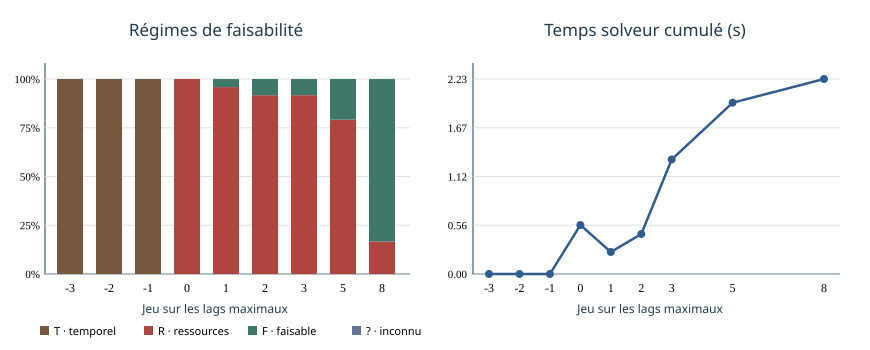

In [9]:
#nullable enable
// Barres empilées et coût cumulé proviennent du même regroupement des essais.
var figure = new StringBuilder("""
<svg xmlns='http://www.w3.org/2000/svg' width='870' height='350' viewBox='0 0 870 350' role='img'>
<title>Trois régimes de faisabilité et temps solveur</title>
<rect width='870' height='350' fill='#fff'/>
<g font-family='sans-serif' fill='#223b4d'>
<text x='216' y='36' text-anchor='middle' font-size='17'>Régimes de faisabilité</text>
<text x='645' y='36' text-anchor='middle' font-size='17'>Temps solveur cumulé (s)</text>
<text x='215' y='313' text-anchor='middle'>Jeu sur les lags maximaux</text>
<text x='650' y='313' text-anchor='middle'>Jeu sur les lags maximaux</text></g>
<path d='M45 63 V274 H410 M473 63 V274 H840' fill='none' stroke='#223b4d'/>
""");
int nRows = summary.Length;
double TimeX(int allowance) => 489 + (allowance - allowances[0]) * 335.0 / (allowances[^1] - allowances[0]);
double maxSeconds = Math.Max(0.1, summary.Max(row => row.Seconds));
double TimeY(double time) => 274 - 195 * time / maxSeconds;
for (int y = 0; y <= 4; y++)
{
    double percentY = 274 - 195 * y / 4.0;
    double time = maxSeconds * y / 4;
    figure.Append(CultureInfo.InvariantCulture,
        $"<path d='M45 {percentY:F1} H410 M473 {TimeY(time):F1} H840' stroke='#dbe4eb'/>" +
        $"<text x='40' y='{percentY+4:F1}' text-anchor='end' font-size='11'>{25*y}%</text>" +
        $"<text x='467' y='{TimeY(time)+4:F1}' text-anchor='end' font-size='11'>{time:F2}</text>");
}
var points = new List<string>();
var hues = new[] { "#78583d", "#af453e", "#3d786a", "#607593" };
for (int i = 0; i < nRows; i++)
{
    var row = summary[i];
    double x = 57 + i * 39;
    double y = 274;
    var ratings = new[] { row.Temporal, row.Resources, row.Feasible, row.Unknown };
    for (int r = 0; r < ratings.Length; r++)
    {
        double height = 195.0 * ratings[r] / ratings.Sum();
        y -= height;
        figure.Append(CultureInfo.InvariantCulture, $"<rect x='{x:F1}' y='{y:F1}' width='26' height='{height:F1}' fill='{hues[r]}'/>");
    }
    double tx = TimeX(row.Allowance);
    double ty = TimeY(row.Seconds);
    figure.Append(CultureInfo.InvariantCulture,
        $"<text x='{x+13:F1}' y='292' text-anchor='middle' font-size='12'>{row.Allowance}</text>" +
        $"<text x='{tx:F1}' y='292' text-anchor='middle' font-size='12'>{row.Allowance}</text>");
    points.Add(FormattableString.Invariant($"{tx:F1},{ty:F1}"));
}
figure.Append($"<polyline points='{string.Join(" ", points)}' fill='none' stroke='#315c8f' stroke-width='2.5'/>");
foreach (var row in summary)
    figure.Append(CultureInfo.InvariantCulture, $"<circle cx='{TimeX(row.Allowance):F1}' cy='{TimeY(row.Seconds):F1}' r='4' fill='#315c8f'/>");
var legend = new[] { "T · temporel", "R · ressources", "F · faisable", "? · inconnu" };
for (int i = 0; i < legend.Length; i++)
    figure.Append($"<rect x='{40+104*i}' y='326' width='9' height='9' fill='{hues[i]}'/><text x='{54+104*i}' y='335' font-family='sans-serif' font-size='11'>{legend[i]}</text>");
figure.Append("</svg>");
display(new SvgFigure(figure.ToString()));

La courbe de droite cumule les temps de CP-SAT pour les instances de chaque jeu.
Elle reste à zéro dans la zone où le circuit positif suffit à trancher.

Dans cette exécution C#, le cumul le plus élevé apparaît au jeu $8$, où la plupart
des instances sont faisables. Le passage de $5$ à $8$ élargit les fenêtres et modifie
la répartition des verdicts. Le graphique ne permet pas d’attribuer la variation
du temps à la seule proportion de cas faisables.

C'est un argument d'ingénierie autant que de théorie : sur un modèle RCPSP/max, **tester le
circuit positif avant d'appeler le solveur** n'est pas une optimisation cosmétique. Sur ce
balayage, cela retire au solveur le tiers gauche du domaine — 72 instances sur 216, traitées
sans lui — et fournit en prime un témoin lisible là où il n'aurait rendu qu'un mot.

## 7. Une borne gratuite — et ce qu'elle vaut vraiment

Changeons de fil. Un banc d'essai compare des solutions à une **référence**. Quand la référence
est disponible et comparable, l'écart est directement interprétable. Quand elle manque, il faut
bien mesurer quelque chose — sinon la colonne reste vide.

Or deux bornes inférieures s'obtiennent sans aucune référence externe :

- le **chemin critique** $\text{CP}$ — plus long chemin dans le réseau, ressources ignorées ;
- la **borne de charge** $\text{LB}_{\text{ch}} = \max_r \lceil \sum_j d_j \cdot r_{jr} / K_r \rceil$
  — le travail total à écouler sur la ressource la plus sollicitée, précédences ignorées.

Chacune relâche une moitié du problème, et leur maximum est une borne inférieure valide. Un
écart mesuré contre cette borne est plus faible qu'un écart à l'optimum connu — mais il est
**calculable**, **toujours disponible** et **honnête sur son propre statut**.

In [10]:
#nullable enable
int LoadBound(RcpspInstance instance)
{
    // Chaque ressource écoule son travail total à un débit borné par sa capacité.
    // La charge totale est en unités ressource-temps. La capacité par instant donne une borne.
    return instance.Capacity.Select((capacity, r) => capacity > 0
        ? (int)Math.Ceiling(instance.Tasks.Sum(i => instance.Durations[i] * instance.Needs[i][r]) / (double)capacity)
        : 0).DefaultIfEmpty().Max();
}

record BoundsRun(double Density, int Seed, int Critical, int Load, int Combined,
    int? SolverBound, int? Makespan, string Status, double? GapPercent, string Stronger, double Seconds);

BoundsRun BoundsLadder(RcpspInstance instance, double density, int seed)
{
    int critical = CriticalPath(instance).Length;
    int load = LoadBound(instance);
    int combined = Math.Max(critical, load);
    // On compare les deux bornes structurelles à la borne de recherche et à l’incumbent du même cas.
    var report = SolveRcpsp(instance, PrecedenceNetwork(instance), 3 * instance.Durations.Sum() + 20);
    if (report.Makespan is int actual && (!report.Valid || actual < combined))
        throw new InvalidOperationException("La solution est invalide ou contredit une borne mathématique.");
    double? gap = report.Makespan is int incumbent && combined > 0
        ? Math.Round((incumbent - combined) * 100.0 / combined, 1) : null;
    return new(density, seed, critical, load, combined, report.SolverBound, report.Makespan,
        report.Status, gap, critical >= load ? "chemin critique" : "charge", report.Seconds);
}

var densities = new[] { 0.10, 0.18, 0.28, 0.40, 0.55 };
var bounds = (from density in densities
              from seed in Enumerable.Range(0, 4)
              let instance = RandomInstance(16, seed, density)
              select BoundsLadder(instance, density, seed)).ToArray();
Console.WriteLine("Densité | Graine | Critique | Charge | Combinée | Makespan | Statut        | Écart (%) | Active");
foreach (var row in bounds)
    Console.WriteLine($"{row.Density,7:F2} | {row.Seed,6} | {row.Critical,8} | {row.Load,6} | {row.Combined,8} | " +
        $"{row.Makespan,8} | {row.Status,-13} | {row.GapPercent,9:F1} | {row.Stronger}");
foreach (var group in bounds.GroupBy(row => row.Density))
    Console.WriteLine($"Densité {group.Key:F2} | chemin critique dominant : {group.Count(row => row.Stronger == "chemin critique")}/4 | " +
        $"écart moyen à la borne {group.Average(row => row.GapPercent):F1} %");
Console.WriteLine($"Borne combinée exacte : {bounds.Count(row => row.GapPercent == 0)}/{bounds.Length}.");

Densité | Graine | Critique | Charge | Combinée | Makespan | Statut        | Écart (%) | Active


   0.10 |      0 |       12 |     34 |       34 |       40 | OPTIMAL       |      17.6 | charge


   0.10 |      1 |       11 |     31 |       31 |       34 | OPTIMAL       |       9.7 | charge


   0.10 |      2 |       13 |     31 |       31 |       38 | OPTIMAL       |      22.6 | charge


   0.10 |      3 |       13 |     29 |       29 |       40 | FEASIBLE      |      37.9 | charge


   0.18 |      0 |       20 |     34 |       34 |       40 | OPTIMAL       |      17.6 | charge


... (17 outputs left out)

Densité 0.28 | chemin critique dominant : 0/4 | écart moyen à la borne 28.5 %


Densité 0.40 | chemin critique dominant : 1/4 | écart moyen à la borne 31.7 %


Densité 0.55 | chemin critique dominant : 2/4 | écart moyen à la borne 25.1 %


Borne combinée exacte : 0/20.


Le tableau de synthèse répond à la question posée : **quelle moitié du problème faut-il
relâcher ?** Aux faibles densités de précédences, la borne de charge domine partout ; le graphe
est trop plat pour qu'une chaîne de tâches pèse quoi que ce soit. En augmentant la densité,
le chemin critique commence à prendre la tête sur quelques instances. La colonne `borne_active`
n'est donc pas une propriété du problème RCPSP en général : c'est une propriété de l'instance,
et la densité de précédences en est le levier. Une seule des deux bornes, prise isolément,
serait très lâche sur toute une moitié du balayage.

Le second chiffre est celui qu'il faut regarder en face : **l'écart à la borne combinée n'est
nul sur aucune de ces instances**. La borne ne touche jamais l'optimum ici. Ce n'est pas une
faiblesse de la borne — c'est une propriété du générateur aléatoire, et le contraste avec la
section suivante est instructif : sur les dix instances PSPLIB observées, le chemin critique
seul atteint l'optimum dans **la moitié des cas**. Un générateur aléatoire ne reproduit pas la
structure d'un benchmark ; les instances de la littérature ont été construites, pas tirées.

Reste la conséquence pratique, valable dans les deux cas. Quand l'écart est strictement positif,
il faut dire ce qu'on mesure : *une distance à une borne calculée*, pas *une distance à
l'optimum connu*. Ce sont deux affirmations différentes, et les confondre est précisément ce
qu'un contrat de provenance doit empêcher.

### Exercice 3 — Retrouver la borne de charge

Complétez `ExerciseLoadBound`. Pour chaque ressource, multipliez la durée de chaque tâche par son besoin, sommez puis calculez le plafond du quotient par la capacité. Retournez la plus forte borne. Les six cas de contrôle utilisent les graines 100 à 105.

In [11]:
#nullable enable
// Exercice 3 : comparer l'effort total au débit maximal pour chaque ressource.
int? ExerciseLoadBound(RcpspInstance instance)
{
    // TODO étudiant : calculer la borne de charge la plus forte.
    return null;
}
int comparedLoads = 0;
int correctLoads = 0;
for (int seed = 0; seed < 6; seed++)
{
    var instance = RandomInstance(14, 100 + seed);
    var proposed = ExerciseLoadBound(instance);
    if (proposed is int value)
    {
        comparedLoads++;
        int expected = LoadBound(instance);
        if (value == expected) correctLoads++;
        Console.WriteLine($"Graine {100 + seed} | borne proposée {value} | référence {expected}");
    }
}
Console.WriteLine(comparedLoads == 0 ? "Exercice 3 à compléter." : $"{correctLoads}/6 bornes correctes.");

Exercice 3 à compléter.


Cette borne ignore complètement les précédences, comme le chemin critique ignore complètement
les ressources. Aucune des deux n'est bonne seule ; leur maximum l'est souvent assez pour
qualifier un résultat quand aucune référence externe n'est disponible.

C'est ce que la section 7 mesurait, et ce sur quoi le contrat de repli de la section 8 s'appuie.

## 8. Quand la jointure échoue en silence

Reste la question de départ : *que vaut ma référence ?* Un banc d'essai qui charge ses
instances par `sorted(glob(...))[:k]` et qui les rapproche d'une table de références indexée
par nom fait reposer toute sa colonne d'écart sur un accord de chaînes de caractères.

Or l'ordre lexicographique n'est pas l'ordre numérique. Dans les noms PSPLIB, le chiffre `0`
vaut `0x30` et le souligné `_` vaut `0x5F` : `j3010_1` précède donc `j301_1`. Une sélection des
dix premiers fichiers ne renvoie pas la famille de paramètres qu'on croit, et une table clavetée
sur l'autre famille ne trouve alors rien.

L'échec est silencieux : la recherche par nom n'aboutit pas et l'écart manque, et la colonne
s'affiche vide sans qu'aucune erreur ne soit levée.

In [12]:
#nullable enable
var psplibNames = Enumerable.Range(1, 10).Select(k => $"j301_{k}")
    .Concat(Enumerable.Range(1, 10).Select(k => $"j3010_{k}")).ToArray();
var shuffler = new SeededDraws(7);
for (int endName = psplibNames.Length - 1; endName > 0; endName--)
{
    int j = shuffler.NextInclusive(0, endName);
    (psplibNames[endName], psplibNames[j]) = (psplibNames[j], psplibNames[endName]);
}
var ordinal = psplibNames.OrderBy(name => name, StringComparer.Ordinal).Take(10).ToArray();
var nameReferences = Enumerable.Range(1, 10).ToDictionary(k => $"j301_{k}", k => 40 + k);
Console.WriteLine($"Tri ordinal : {string.Join(", ", ordinal)}");
Console.WriteLine($"j301_* : {ordinal.Count(n => n.StartsWith("j301_", StringComparison.Ordinal))}/10 | " +
    $"j3010_* : {ordinal.Count(n => n.StartsWith("j3010_", StringComparison.Ordinal))}/10");
Console.WriteLine($"'j3010_1' précède 'j301_1' : {StringComparer.Ordinal.Compare("j3010_1", "j301_1") < 0}");
Console.WriteLine($"Jointure par nom après tri ordinal : {ordinal.Count(nameReferences.ContainsKey)}/10.");

(int Family, int Parameter, int Index) PsplibSortKey(string name)
{
    // Le paramètre numérique ne doit pas faire passer le groupe 30/10 avant 30/1.
    var parts = name.Split('_', 2);
    var head = parts[0].TrimStart('j');
    foreach (int family in new[] { 120, 30, 60, 90 })
    {
        string digits = family.ToString(CultureInfo.InvariantCulture);
        if (!head.StartsWith(digits, StringComparison.Ordinal)) continue;
        var suffix = head[digits.Length..];
        int param = suffix.Length == 0 ? 0 : int.Parse(suffix, CultureInfo.InvariantCulture);
        int index = parts.Length < 2 ? 0 : int.Parse(parts[1], CultureInfo.InvariantCulture);
        return (family, param, index);
    }
    return (int.MaxValue, 0, 0);
}
var numeric = psplibNames.OrderBy(PsplibSortKey).Take(10).ToArray();
Console.WriteLine($"Tri (famille, paramètre, indice) : {string.Join(", ", numeric)}");
Console.WriteLine($"Jointure par nom après tri numérique : {numeric.Count(nameReferences.ContainsKey)}/10.");

Tri ordinal : j3010_1, j3010_10, j3010_2, j3010_3, j3010_4, j3010_5, j3010_6, j3010_7, j3010_8, j3010_9


j301_* : 0/10 | j3010_* : 10/10


'j3010_1' précède 'j301_1' : True


Jointure par nom après tri ordinal : 0/10.


Tri (famille, paramètre, indice) : j301_1, j301_2, j301_3, j301_4, j301_5, j301_6, j301_7, j301_8, j301_9, j301_10


Jointure par nom après tri numérique : 10/10.


Dix lignes, aucune référence trouvée, aucune exception. C'est le mode de défaillance le plus
coûteux : le programme continue, produit un tableau d'apparence normale, et seule la lecture
attentive d'une colonne vide révèle que la comparaison n'a jamais eu lieu.

Le protocole est ici en cause, jamais les auteurs : dans le rendu source, **les dix makespans
publiés sont exacts** — ils ont été recalculés indépendamment pour cet audit et tous confirmés
`OPTIMAL`. Ce qui manque n'est pas un résultat, c'est la garantie qu'une comparaison manquée
se signale.

Frontieres-07 a déjà doté CoursIA du premier volet : **refuser** une jointure dont l'identité
structurelle ne correspond pas. Le volet complémentaire est celui-ci : **sur quoi se rabattre
quand la référence manque légitimement ?**

In [13]:
#nullable enable
record ReferenceValue(int Value, string Origin);

string PythonArray(IEnumerable<int> values) => $"[{string.Join(", ", values)}]";

string StructuralHash(RcpspInstance instance)
{
    // Les propriétés triées et les espaces reproduisent le JSON source avant le hash.
    string edges = string.Join(", ", instance.Precedences.OrderBy(a => a.From).ThenBy(a => a.To)
        .Select(arc => PythonArray(new[] { arc.From, arc.To })));
    string demands = string.Join(", ", instance.Needs.Select(PythonArray));
    string content = $$"""{"arcs": [{{edges}}], "besoins": [{{demands}}], "capacites": {{PythonArray(instance.Capacity)}}, "durees": {{PythonArray(instance.Durations)}}, "n": {{instance.Count}}}""";
    return Convert.ToHexStringLower(SHA256.HashData(Encoding.UTF8.GetBytes(content)))[..16];
}

(string Reference, int Value, string Evidence, double GapPercent) EvaluateWithFallback(
    RcpspInstance instance, int makespan, IReadOnlyDictionary<string, ReferenceValue> references)
{
    // Seule la clé de structure autorise la comparaison à une référence préexistante.
    if (references.TryGetValue(StructuralHash(instance), out var linked))
        return ("référence appariée", linked.Value, linked.Origin,
            Math.Round((makespan - linked.Value) * 100.0 / linked.Value, 1));
    int bound = Math.Max(CriticalPath(instance).Length, LoadBound(instance));
    return ("borne calculée", bound, "borne inférieure certifiée (chemin critique / charge)",
        Math.Round((makespan - bound) * 100.0 / bound, 1));
}
var joinCase = RandomInstance(16, 3, 0.22);
var joinSolved = SolveRcpsp(joinCase, PrecedenceNetwork(joinCase), 3 * joinCase.Durations.Sum() + 20);
if (!joinSolved.Valid || joinSolved.Status != "OPTIMAL" ||
    joinSolved.Makespan is not int joinMakespan || joinSolved.SolverBound != joinMakespan)
    throw new InvalidOperationException("La jointure de démonstration exige un optimum local certifié.");
var joinKey = StructuralHash(joinCase);
Console.WriteLine($"Empreinte de l'instance témoin : {joinKey} | makespan recalculé {joinMakespan}");
foreach (var (label, references) in new[]
{
    ("identité connue", new Dictionary<string, ReferenceValue> { [joinKey] = new(joinMakespan, "optimum CP-SAT local du témoin") }),
    ("identité absente", new Dictionary<string, ReferenceValue>()),
    ("nom identique, autre structure", new Dictionary<string, ReferenceValue> { [new string('0', 16)] = new(999, "référence factice à rejeter") })
})
{
    var result = EvaluateWithFallback(joinCase, joinMakespan, references);
    Console.WriteLine($"{label,-29} → {result.Reference,-15} {result.Value,4} | écart {result.GapPercent:F1} % | {result.Evidence}");
}

Empreinte de l'instance témoin : 594787df092167e7 | makespan recalculé 43


identité connue               → référence appariée   43 | écart 0.0 % | optimum CP-SAT local du témoin


identité absente              → borne calculée    29 | écart 48.3 % | borne inférieure certifiée (chemin critique / charge)


nom identique, autre structure → borne calculée    29 | écart 48.3 % | borne inférieure certifiée (chemin critique / charge)


Le contraste est net. La référence appariée du témoin est l’optimum local certifié par CP-SAT. Cette référence synthétique illustre le test d’identité. Les observations PSPLIB proviennent du banc historique présenté ensuite. Quand elle manque — pour quelque raison que ce soit, jointure ratée, instance nouvelle,
table incomplète — l'évaluation ne se tait pas : elle se rabat sur une borne calculée et **le
dit** dans le champ de provenance.

La différence avec une colonne vide n'est pas cosmétique. Une colonne vide n'affirme rien et
n'alerte pas. L'écart de 48,3 % à une borne inférieure certifiée affiché ci-dessus est une
information réelle — faible, puisque la borne est lâche, mais utilisable, et surtout impossible
à confondre avec un écart à l'optimum. Le champ de provenance porte cette distinction dans
la donnée elle-même, pas seulement dans le commentaire qui l'accompagne.

## 9. Ce que le snapshot source donne à voir

La bibliothèque PSPLIB n'est pas redistribuée par CoursIA. En revanche, les dix instances que
le banc d'essai source sélectionne effectivement ont été identifiées par empreinte SHA-256 et
remesurées pour cet audit avec un modèle indépendant. Les mesures sont reproduites ci-dessous
telles quelles, à titre d'observation datée.

La colonne `optimum` n'est pas une valeur recopiée d'une table publiée : c'est le makespan
**recalculé** pour cet audit, d'où le statut `OPTIMAL` et le temps de résolution portés par
chaque ligne. Les dix lignes ont été rejouées une seconde fois le 2026-09-07, à partir d'un
parseur et d'un modèle réécrits indépendamment : les dix optima et les dix chemins critiques
se reproduisent à l'identique. Ce second passage a en revanche corrigé une **empreinte**
mal transcrite (`j12010_10`, un caractère). L'ironie est instructive et sur le sujet même de
la section précédente : une colonne recopiée à la main dérive, y compris celle dont le rôle
est de détecter la dérive — c'est précisément pourquoi `StructuralHash` recalcule l'empreinte
au lieu de lui faire confiance.

In [14]:
#nullable enable
record PsplibObservation(string Instance, string Hash, int Critical, int Optimum, string Status, double Seconds);
var provenancePath = Path.Combine("data", "app31-rcpsp-max", "provenance.json");
if (!File.Exists(provenancePath))
    provenancePath = Path.Combine("MyIA.AI.Notebooks", "Search", "Part5-Frontieres", provenancePath);
var archive = JsonDocument.Parse(File.ReadAllText(provenancePath));
var observations = archive.RootElement.GetProperty("observations_psplib").EnumerateArray()
    .Select(row => new PsplibObservation(
        row.GetProperty("instance").GetString()!, row.GetProperty("sha256_16").GetString()!,
        row.GetProperty("chemin_critique").GetInt32(), row.GetProperty("optimum_recalcule").GetInt32(),
        row.GetProperty("statut").GetString()!, row.GetProperty("temps_verification_s").GetDouble())).ToArray();

// Les dix mesures sont les observations d'audit publiées. Seuls leurs écarts sont recalculés ici.
Console.WriteLine("Observations du banc source | instance     | empreinte        | Critique | Optimum | Statut  | Temps (s) | Écart");
foreach (var row in observations)
    Console.WriteLine($"                             {row.Instance,-13} | {row.Hash} | {row.Critical,8} | {row.Optimum,7} | " +
        $"{row.Status,-7} | {row.Seconds,9:F2} | {row.Optimum - row.Critical,5}");
Console.WriteLine($"Chemin critique égal à l'optimum sur {observations.Count(row => row.Critical == row.Optimum)}/{observations.Length} observations.");
Console.WriteLine($"Temps consignés dans le banc : {observations.Min(row => row.Seconds):F2}–{observations.Max(row => row.Seconds):F2} s.");

Observations du banc source | instance     | empreinte        | Critique | Optimum | Statut  | Temps (s) | Écart


                             j30/j3010_1   | 4fae4197791f2ee8 |       41 |      42 | OPTIMAL |      0.06 |     1


                             j30/j3010_10  | 5b704056bfd6531d |       37 |      41 | OPTIMAL |      0.05 |     4


                             j30/j3010_2   | 108f260686ec9353 |       52 |      56 | OPTIMAL |      0.04 |     4


                             j30/j3010_3   | de28125e10ed4379 |       61 |      62 | OPTIMAL |      0.03 |     1


                             j30/j3010_4   | 5526e62c26ae880e |       53 |      58 | OPTIMAL |      0.05 |     5


... (3 outputs left out)

                             j120/j12010_1 | 99dd309553f879c2 |      111 |     111 | OPTIMAL |      0.07 |     0


                             j120/j12010_10 | 6620267bb213583b |       66 |      66 | OPTIMAL |      0.08 |     0


Chemin critique égal à l'optimum sur 5/10 observations.


Temps consignés dans le banc : 0.03–0.08 s.


Deux lectures, qu'il faut tenir séparées.

**Ce que la table établit.** Sur cinq des dix instances effectivement sélectionnées, le chemin
critique **touche déjà l'optimum**. Là, une évaluation par repli sur borne calculée aurait été
aussi informative qu'une comparaison à l'optimum publié : l'écart mesuré aurait été le bon, à
zéro près. Sur les cinq autres, la borne est optimiste de 1 à 5 unités, et le repli l'aurait
signalé comme tel.

**Ce qu'elle n'établit pas.** Que ces cinq instances seraient « faciles », ou que leurs
ressources seraient inactives. Elles ne le sont pas : sur chacune, la capacité disponible est
très inférieure au pic de demande de l'ordonnancement au plus tôt, lequel est donc irréalisable.
Les ressources imposent bel et bien une réorganisation — simplement, elles n'imposent aucun
retard. Le critère « capacité supérieure au pic au plus tôt » est *suffisant* pour garantir que
l'optimum vaut le chemin critique ; il n'est pas *nécessaire*, et ces cinq instances en sont le
contre-exemple.

Enfin, la vitesse de résolution ne s'explique pas par cette coïncidence : les cinq instances où
la borne est lâche se résolvent tout aussi vite. Les deux observations sont indépendantes, et
les rapprocher serait une inférence non fondée.

In [15]:
#nullable enable
// Séparer la provenance archivée des mesures courantes dans les artefacts exportés.
var provenance = new
{
    notebook = "Frontieres-09-RCPSP-Max-Feasibility-Bounds-CSharp",
    objet = "RCPSP/max : faisabilité, circuits positifs, hiérarchie de bornes",
    source_distillee = archive.RootElement.GetProperty("source_distillee").Clone(),
    environnement = environment,
    instances = "Réseaux et besoins engendrés avec les graines du carnet Python, y compris le tirage des lags.",
    observations_psplib = observations,
    preuve_psplib = "Les mesures PSPLIB proviennent de l'audit archivé. Les expériences synthétiques sont recalculées."
};
void WriteReport(string filename, object report) =>
    File.WriteAllText(Path.Combine(reportDirectory.FullName, filename), JsonSerializer.Serialize(report, jsonOptions));
WriteReport("provenance.json", provenance);
WriteReport("bounds_ladder.json", new
{
    definition = new
    {
        chemin_critique = "Plus long chemin ignorant les ressources.",
        borne_charge = "Maximum des plafonds travail total / capacité par ressource.",
        borne_combinee = "Maximum des deux bornes."
    },
    instances = bounds
});
string Csv(RegimeRun row) => FormattableString.Invariant(
    $"{row.Allowance},{row.Seed},{row.LagCount},{row.Regime},{row.Status},{row.Makespan},{row.Seconds:R},{row.Witness},{row.Valid}");
File.WriteAllLines(Path.Combine(reportDirectory.FullName, "temporal_regimes.csv"),
    new[] { "jeu,graine,lags,regime,statut,makespan,secondes,temoin,valide" }.Concat(regimes.Select(Csv)));
foreach (var report in reportDirectory.EnumerateFiles().OrderBy(file => file.Name))
    Console.WriteLine($"{report.Name,-24} {report.Length,8} octets");

bounds_ladder.json           5670 octets


provenance.json              2570 octets


temporal_regimes.csv         8076 octets


Les trois artefacts portent chacun un niveau de preuve distinct : `provenance.json` fixe
l'identité et l'environnement, `temporal_regimes.csv` conserve la classification et les témoins
de circuit, `bounds_ladder.json` documente la formule de chaque borne à côté de ses valeurs. Un
chiffre séparé de sa définition n'est pas reproductible ; c'est pourquoi les définitions
voyagent avec les données.

## Hommage au projet B4 — l'exercice que le cours différait

Le rendu d'**Arthur Gallier** et **Nicolas Naegelen** a fait ce que `Planners-08-Temporal-Python`
laissait explicitement « en exercice » : confronter un solveur à un benchmark public
d'ordonnancement, et mettre en regard l'exact et l'approché. Ce n'est pas une petite chose. Il
a fallu écrire un parseur `.sm`, modéliser proprement les cumulatives, construire une baseline
génétique dont le croisement préserve les précédences, et faire tourner tout cela sur trois
tailles d'instances.

La vérification indépendante conduite pour cet audit conclut sur ce point sans réserve : **les
dix makespans publiés sont exacts**, tous certifiés `OPTIMAL` par un modèle réécrit de zéro. Le
« j120 résolu en une fraction de seconde », qui pouvait surprendre, est confirmé lui aussi : la
table de la section 9 en donne le temps de vérification, et la plus grosse instance reste sous
le dixième de seconde. Il n'y avait rien à corriger dans ces résultats.

Ce que ce notebook prolonge se situe ailleurs, sur deux points que leur travail rendait
visibles :

- leur section RCPSP/max pose le **bon modèle général**, capable de porter des lags maximaux ;
  Frontieres-09 exerce ce que ce modèle rend possible et que la formulation seule ne montre pas — le
  circuit, le témoin, la bascule de complexité ;
- leur banc d'essai fait reposer sa colonne d'écart sur une jointure par nom ; App-31 en tire
  la question de protocole, non pour corriger un chiffre, mais pour que l'absence de référence
  cesse d'être silencieuse.

Leur structure anticipait d'ailleurs plus qu'elle n'exploitait : la section multi-mode existe
déjà côté CP-SAT, prête pour une comparaison exact/approché que la baseline génétique, restée
mono-mode, ne pouvait pas encore fournir. C'est une extension naturelle de leur propre
architecture, pas une lacune.

## Bilan critique — ce que ce notebook autorise à affirmer

### Ce qui est établi

- Un lag maximal s'encode par un **arc inverse** et referme un circuit ; un décalage minimal
  négatif, non. La distinction est structurelle, pas une affaire de signe.
- Un système de contraintes de différences est faisable **si et seulement si** aucun circuit
  n'est de poids strictement positif. Le témoin exhibé se vérifie à la main.
- En RCPSP pur, l'ordonnancement série ne se bloque jamais — 300 instances, zéro échec — parce
  qu'aucune contrainte n'interdit de repousser une tâche. Avec des lags maximaux, cette garantie
  disparaît et la **faisabilité** devient NP-difficile (Bartusch, Möhring, Radermacher, 1988).
- Tester le circuit positif avant d'appeler le solveur supprime tout coût de recherche sur le
  tiers gauche du domaine balayé — 72 instances sur 216, jamais soumises au solveur — et rend un
  diagnostic lisible là où le solveur ne rendrait qu'un mot.
- Chemin critique et borne de charge relâchent chacun une moitié du problème ; **laquelle domine
  dépend de l'instance**, et la densité de précédences en est le levier mesurable.
- Le maximum des deux bornes est exact sur cinq des dix instances PSPLIB observées, et sur
  **aucune** des vingt instances aléatoires du balayage. Un générateur aléatoire ne reproduit pas
  la structure d'un benchmark construit.

### Ce qui n'est pas établi

- Que les cinq instances PSPLIB dont l'optimum touche le chemin critique auraient des ressources
  « inactives » : leur capacité est très inférieure au pic de l'ordonnancement au plus tôt. Les
  ressources y imposent une réorganisation, non un retard.
- Que la coïncidence borne/optimum expliquerait la vitesse de résolution : les instances où la
  borne est lâche se résolvent tout aussi vite. Les deux observations sont indépendantes.
- Aucune performance générale. Les mesures portent sur de petites instances synthétiques, un
  solveur, une machine et des budgets publiés. Elles enseignent un protocole.
- `INFEASIBLE` sous budget fini n'est concluant que si le solveur le déclare ; un budget épuisé
  ne prouve rien.

### À retenir

1. **Le lag maximal et le décalage minimal ne sont pas deux variantes du même arc** : sur le réseau du carnet, les seules précédences donnent 3 arcs sans circuit ; ajouter un décalage minimal négatif porte le graphe à 4 arcs, toujours sans circuit ; ajouter un lag maximal laisse 4 arcs mais **referme un circuit**. Le nombre d'arcs est le même, la structure ne l'est pas — la distinction est structurelle, pas une affaire de signe.
2. **Un seuil suffit à rendre le système infaisable, et le solveur exhibe le témoin** : avec `lag maximal <= 6`, le réseau est `FAISABLE` et les dates au plus tôt sont `[0, 3, 7, 9]` ; dès `lag maximal <= 5`, il devient `INFAISABLE` et le solveur montre le circuit `3 -> 1 -> 2 -> 3` de poids `+1`, puis `+2` à `lag maximal <= 4` et `+3` à `lag maximal <= 3`. Un arc de trop suffit à fermer la faisabilité.
3. **Le RCPSP pur est confortable, pas facile** : 300 instances aléatoires, ordonnancement série en échec **0 fois** — parce qu'aucune contrainte n'interdit de repousser une tâche. Le passage aux lags maximaux retire cette garantie et rend la faisabilité NP-difficile (Bartusch, Möhring, Radermacher, 1988).
4. **Le diagnostic temporel évite des appels à CP-SAT**. Sur les 216 instances à 14 tâches du balayage, le diagnostic tranche les trois jeux négatifs (24 instances par jeu). Le tableau enregistre zéro seconde de CP-SAT pour ces instances. Dès que le réseau devient admissible, la question change de classe : à jeu nul, les 24 instances sont déclarées admissibles puis toutes déclarées infaisables (régime R). Entre les jeux 5 et 8, le nombre d'instances faisables passe de 5 à 20 sur 24. Le temps cumulé de CP-SAT augmente aussi dans cette exécution C#. Ce tableau compare des groupes d'instances aux fenêtres différentes et ne permet pas d'isoler le coût d'une preuve d'infaisabilité.
5. **La référence doit être nommée, sinon l'écart n'a pas de sens** : quand l'identité de l'instance concorde, la référence est l'optimum publié (`valeur= 43 ecart= 0.0%`) ; quand elle est absente, la référence devient une borne calculée (`valeur= 29 ecart= 48.3%`). Les deux chiffres ne mesurent pas la même chose, et un contrat de provenance doit dire lequel des deux il rapporte.
6. **Une borne gratuite n'est exacte que là où la structure a été construite** : sur le balayage aléatoire des densités, l'écart à la borne combinée n'est nul sur **aucune** instance (`0/20`), alors que sur les dix instances PSPLIB le chemin critique touche déjà l'optimum sur **5** d'entre elles. Un générateur aléatoire ne reproduit pas un benchmark construit.
7. **Une jointure ratée ne lève pas d'exception : elle produit une colonne vide** : `sorted(...)[:10]` renvoie 10/10 noms de la famille `j3010_*`, et la jointure par nom ne retrouve **aucune** référence (`0/10`) — sans erreur levée, la colonne d'écart reste vide. Le tri par clé PSPLIB rétablit 10/10.

### Vérifiez votre compréhension

1. **Sur le réseau du carnet, les seules précédences donnent 3 arcs sans circuit ; l'ajout d'un décalage minimal négatif porte le graphe à 4 arcs, toujours sans circuit ; l'ajout d'un lag maximal laisse 4 arcs mais referme un circuit. Pourquoi un seul arc supplémentaire suffit-il à changer la nature du problème ?**
2. **À jeu nul, le diagnostic temporel déclare les 24 instances admissibles, puis le solveur les déclare toutes infaisables (régime R). Quel est le gain exact du pré-test, et que ne peut-il pas apporter ?**
3. **Sur le balayage des densités, l'écart à la borne combinée n'est nul sur aucune instance (0/20) ; sur les dix instances PSPLIB, le chemin critique touche déjà l'optimum sur 5 d'entre elles. Que peut-on affirmer d'une borne combinée, et que doit-on écrire dans un contrat de provenance ?**
4. **`sorted(...)[:10]` renvoie 10/10 noms `j3010_*`, et la jointure par nom ne retrouve aucune référence (0/10) sans lever aucune erreur ; le tri par clé PSPLIB rétablit 10/10. Pourquoi un code qui s'exécute sans erreur peut-il produire un résultat vide ?**

<details>
<summary>Réponses</summary>

1. Parce que les deux contraintes ne s'encodent pas de la même façon. Le décalage minimal est une contrainte de bornes entre deux tâches : il peut être négatif, mais il ne referme aucun cycle. Le lag maximal s'encode par un **arc inverse** entre les deux tâches, et un arc inverse peut fermer un circuit. Le carnet le dit par le nombre d'arcs — 3 puis 4 dans les deux cas — : ce qui change n'est pas la quantité d'arcs mais leur orientation, donc la possibilité d'un cycle de poids strictement positif. C'est la raison pour laquelle le carnet parle d'une distinction **structurelle** et non d'une affaire de signe.
2. Le pré-test retire au solveur le travail des instances dont le réseau temporel tranche déjà à lui seul — les trois jeux négatifs, 24 instances chacun, sans appel à CP-SAT. Il ne change **rien** à la vérité des instances restantes : à jeu nul, le pré-test déclare l'admissibilité, et il faut encore payer la recherche pour conclure à l'infaisabilité. Le pré-test économise des appels à CP-SAT et fournit un témoin que l’on peut relire à la main. C'est d'ailleurs ce basculement d'un bloc à l'autre — 24 instances en régime T à jeu −1, 24 en régime R à jeu 0 — qui rend visible le changement de classe de complexité.
3. Qu'une borne combinée est une **borne inférieure**, pas un optimum : l'écart qu'on rapporte est une distance à une valeur calculée, jamais une distance à l'optimum connu. Sa qualité dépend de la structure de l'instance : sur le générateur aléatoire elle ne touche jamais l'optimum (0/20), sur le PSPLIB elle le touche dans la moitié des cas. Un contrat de provenance doit donc **nommer la référence** — « optimum publié » quand l'identité de l'instance concorde, « borne calculée » sinon — sinon le même mot recouvre deux mesures différentes, et le chiffre devient ininterprétable.
4. Parce qu'une jointure qui ne trouve rien ne lève pas d'exception : elle renvoie une colonne vide, et le pipeline se poursuit sans jamais s'arrêter. Le premier symptôme n'est donc pas une erreur, c'est une **colonne vide** et un écart manquant. Le second piège est dans le tri : le tri lexicographique range `j3010_1` avant `j301_1` (le caractère `'0'` précède `'_'` dans la table ASCII), si bien que la fenêtre sélectionnée ne contient plus que la famille `j3010_*`. Le contrôle qui manque n'est donc pas celui de l'absence d'exception, mais celui de la **couverture** — combien de références ont été retrouvées — comparé au nombre attendu.

</details>

### Pour aller plus loin

- Étendre le témoin de circuit à un **certificat de fenêtre** : quel sous-ensemble de bornes
  supérieures rend l'instance infaisable, et lequel suffit à la rétablir ?
- Rejouer la baseline métaheuristique en multi-mode, extension que la structure du projet source
  rendait déjà accessible côté modèle.
- Comparer la borne de charge à une borne énergétique par fenêtre, strictement plus forte.